<div align="center">

# **Practical 5**
## Text-to-Image Generation with Stable Diffusion using Hugging Face Diffusers
###### Impact of Inference Steps, Guidance Scale and Sampling Methods on Image Quality

| | |
|---|---|
| **Name** | Sanika Mane |
| **PRN** | 202401110047 |
| **Practical No.** | 5 |
| **Date** | 30 October 2026 |

</div>



## 1. Aim and Objectives
**Aim:** Implement a pretrained Stable Diffusion model with the Hugging Face Diffusers library to generate images from text prompts, and analyse how inference settings affect the quality of the generated images.

**Objectives**
1. Load a pretrained Stable Diffusion pipeline and generate images from text prompts.
2. Study the effect of the **number of inference steps**.
3. Study the effect of the **guidance scale** (classifier-free guidance).
4. Compare **nine sampling methods** (schedulers) on quality, convergence and speed.
5. Examine the **interaction** between steps and guidance.
6. Support every conclusion with metrics, graphs and visual comparisons.

## 2. Theory

**Latent diffusion.** Stable Diffusion runs the diffusion process in a compressed latent space with three components: a **CLIP text encoder** (prompt → embeddings), a **U-Net** that predicts the noise in a latent at every step, and a **VAE decoder** that turns the final latent into an image. Generation starts from Gaussian noise, which the U-Net removes step by step.

**Inference steps (T).** Each step is one U-Net evaluation, so cost grows linearly with T. Too few steps leave the latent under-denoised; beyond some point extra steps give diminishing returns.

**Guidance scale (w).** Classifier-free guidance combines two noise predictions, one with the prompt and one without:

$$\epsilon = \epsilon_{uncond} + w\,(\epsilon_{cond} - \epsilon_{uncond})$$

Larger $w$ pushes the sample toward the prompt at the cost of diversity and, when too large, realism. $w = 1$ means no guidance.

**Samplers.** A scheduler is a numerical solver for the reverse diffusion process.

| Sampler | Character |
|---|---|
| PNDM | Pseudo-numerical method, SD v1 default |
| DDIM | Deterministic, first-order |
| LMS | Linear multistep, higher order |
| Euler | First-order ODE solver |
| Euler A | Euler plus re-injected noise (ancestral), stochastic |
| Heun | Second-order, two U-Net calls per step |
| DPM++ 2M | Second-order multistep, fast convergence |
| DPM++ 2M Karras | Same solver with Karras noise spacing |
| UniPC | Predictor-corrector, strong at low step counts |

**Evaluation metrics used**

| Metric | Meaning | Better when |
|---|---|---|
| CLIP score | Cosine similarity of image and prompt embeddings x100 | higher |
| PSNR vs. reference | Closeness to a 100-step DPM++ 2M render (same prompt and seed); measures convergence | higher |
| Sharpness | Variance of the Laplacian of the grayscale image; a proxy for fine detail | context-dependent |
| Contrast | Standard deviation of grayscale intensity | context-dependent |
| Saturation | Mean HSV saturation (%); rises when images become over-saturated | moderate |
| Latency | Seconds per image | lower |

## 3. Environment Setup

In [ ]:
!pip install -q diffusers transformers accelerate safetensors scipy

In [ ]:
import os, time, platform
import numpy as np
import pandas as pd
import torch, diffusers, transformers
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from IPython.display import display, Markdown
from diffusers import (
    StableDiffusionPipeline,
    PNDMScheduler, DDIMScheduler, LMSDiscreteScheduler,
    EulerDiscreteScheduler, EulerAncestralDiscreteScheduler,
    HeunDiscreteScheduler, DPMSolverMultistepScheduler, UniPCMultistepScheduler,
)
from transformers import CLIPModel, CLIPProcessor

STUDENT = {"Name": "Sanika Mane", "PRN": "202401110047", "Practical": "5"}
print(" | ".join(f"{k}: {v}" for k, v in STUDENT.items()))

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
SEED, OUT = 42, "sd_results"
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

env = pd.DataFrame({"Item": ["Python", "PyTorch", "Diffusers", "Transformers", "Device", "Seed"],
                    "Value": [platform.python_version(), torch.__version__, diffusers.__version__, transformers.__version__,
                              torch.cuda.get_device_name(0) if device == "cuda" else "CPU (switch to GPU!)", SEED]})
display(env)

Name: Sanika Mane | PRN: 202401110047 | Practical: 5


,Item,Value
0,Python,3.13.16
1,PyTorch,2.11.0+cu130
2,Diffusers,0.42.0
3,Transformers,5.20.2
4,Device,NVIDIA RTX PRO 6000 Blackwell Server Edition
5,Seed,42


## 4. Loading the Pretrained Model

Run the next code cell after completing Environment Setup. If Hugging Face requests access, sign in and accept the model conditions as explained in the error guidance.


In [ ]:
# Load the pretrained Stable Diffusion v1.5 model
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

print("Loading model:", MODEL_ID)
print("Device:", device, "| Data type:", dtype)

try:
    pipe = StableDiffusionPipeline.from_pretrained(
        MODEL_ID,
        torch_dtype=dtype,
        use_safetensors=True
    )
    pipe = pipe.to(device)
except Exception as e:
    print("\\nModel loading failed.")
    print("If the error mentions 401/403, gated access, or authentication:")
    print("1. Open https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5")
    print("2. Sign in and accept/agree to the model conditions if prompted.")
    print("3. In Colab, run: from huggingface_hub import notebook_login; notebook_login()")
    print("4. Run this cell again.")
    raise e

pipe.set_progress_bar_config(disable=False)
BASE_SCHED_CFG = pipe.scheduler.config

def n_params(model):
    return sum(p.numel() for p in model.parameters()) / 1e6

display(pd.DataFrame({
    "Component": ["Text encoder (CLIP)", "U-Net", "VAE", "Default scheduler"],
    "Detail": [
        f"{n_params(pipe.text_encoder):.0f}M parameters",
        f"{n_params(pipe.unet):.0f}M parameters",
        f"{n_params(pipe.vae):.0f}M parameters",
        type(pipe.scheduler).__name__
    ]
}))


Loading model: stable-diffusion-v1-5/stable-diffusion-v1-5
Device: cuda | Data type: torch.float16


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

,Component,Detail
0,Text encoder (CLIP),123M parameters
1,U-Net,860M parameters
2,VAE,84M parameters
3,Default scheduler,PNDMScheduler


## 5. Basic Text-to-Image Generation

After the model loads successfully, run the next code cell to generate and save a 512 × 512 image.


  0%|          | 0/30 [00:00<?, ?it/s]

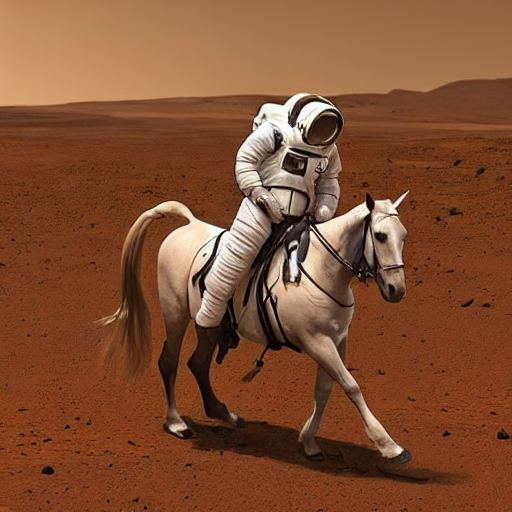

Image saved to: sd_results/basic_generation.png


In [ ]:
# Basic text-to-image generation
prompt = "a photograph of an astronaut riding a horse on mars, highly detailed"
generator = torch.Generator(device=device).manual_seed(SEED)

with torch.inference_mode():
    result = pipe(
        prompt,
        num_inference_steps=30,
        guidance_scale=7.5,
        generator=generator,
        height=512,
        width=512
    )

image = result.images[0]
display(image)
image.save(f"{OUT}/basic_generation.png")
print("Image saved to:", f"{OUT}/basic_generation.png")


## 6. Experimental Framework
- **Identical seed in every run**, so each image starts from the same noise and only the parameter under test changes.
- **Three prompts** in different styles (photo, painting, food photography).
- A shared **negative prompt** and 512x512 output.
- Every image is scored with the metrics defined in section 2 and stored in one results table.

In [ ]:

PROMPTS = [
    "a photograph of an astronaut riding a horse on mars, highly detailed",
    "a cozy wooden cabin in a snowy forest at sunset, oil painting",
    "a bowl of ramen with a soft-boiled egg, studio food photography",
]

PNAMES = ["Astronaut (photo)", "Cabin (painting)", "Ramen (food photo)"]
NEG = "blurry, low quality, distorted, extra limbs"

# Load CLIP model
clip = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
).to(device).eval()

clip_proc = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)


# Calculate CLIP similarity score
@torch.no_grad()
def clip_score(image, prompt):

    inp = clip_proc(
        text=[prompt],
        images=[image],
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(device)

    # Image embeddings
    image_output = clip.vision_model(
        pixel_values=inp["pixel_values"]
    )

    image_features = clip.visual_projection(
        image_output.pooler_output
    )

    # Text embeddings
    text_output = clip.text_model(
        input_ids=inp["input_ids"],
        attention_mask=inp["attention_mask"]
    )

    text_features = clip.text_projection(
        text_output.pooler_output
    )

    # Normalize embeddings
    image_features = torch.nn.functional.normalize(
        image_features, dim=-1
    )

    text_features = torch.nn.functional.normalize(
        text_features, dim=-1
    )

    # Cosine similarity
    score = (image_features * text_features).sum(dim=-1)

    return float(score.item() * 100)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [ ]:
test_image, test_time = generate(
    PROMPTS[0],
    steps=5,
    guidance=7.5,
    sampler="DPM++ 2M"
)

test_score = clip_score(test_image, PROMPTS[0])

print("CLIP Score:", round(test_score, 2))
print("Generation Time:", round(test_time, 2), "seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

CLIP Score: 31.65
Generation Time: 0.12 seconds


## 7. Experiment 1: Effect of Inference Steps
**Fixed:** guidance = 7.5, sampler = DPM++ 2M. **Varied:** steps = 5, 10, 15, 20, 30, 50, 100. The 100-step image is the reference for convergence (PSNR).

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

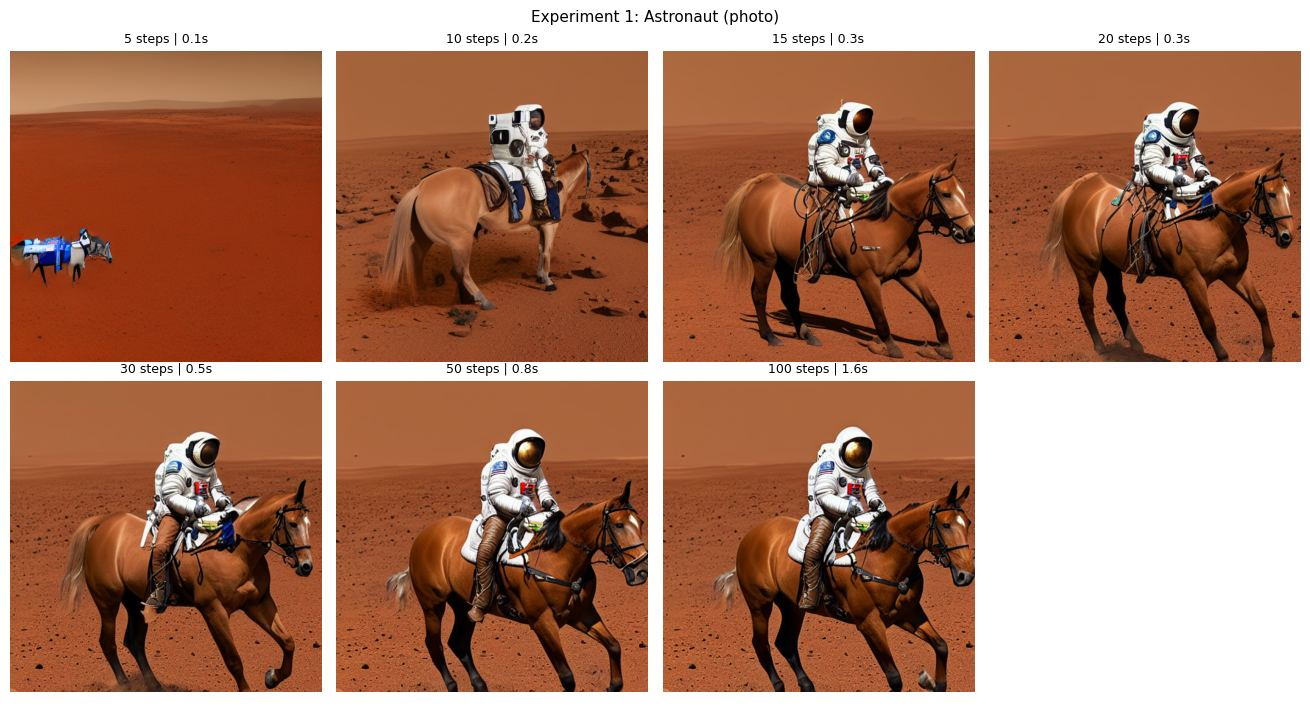

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

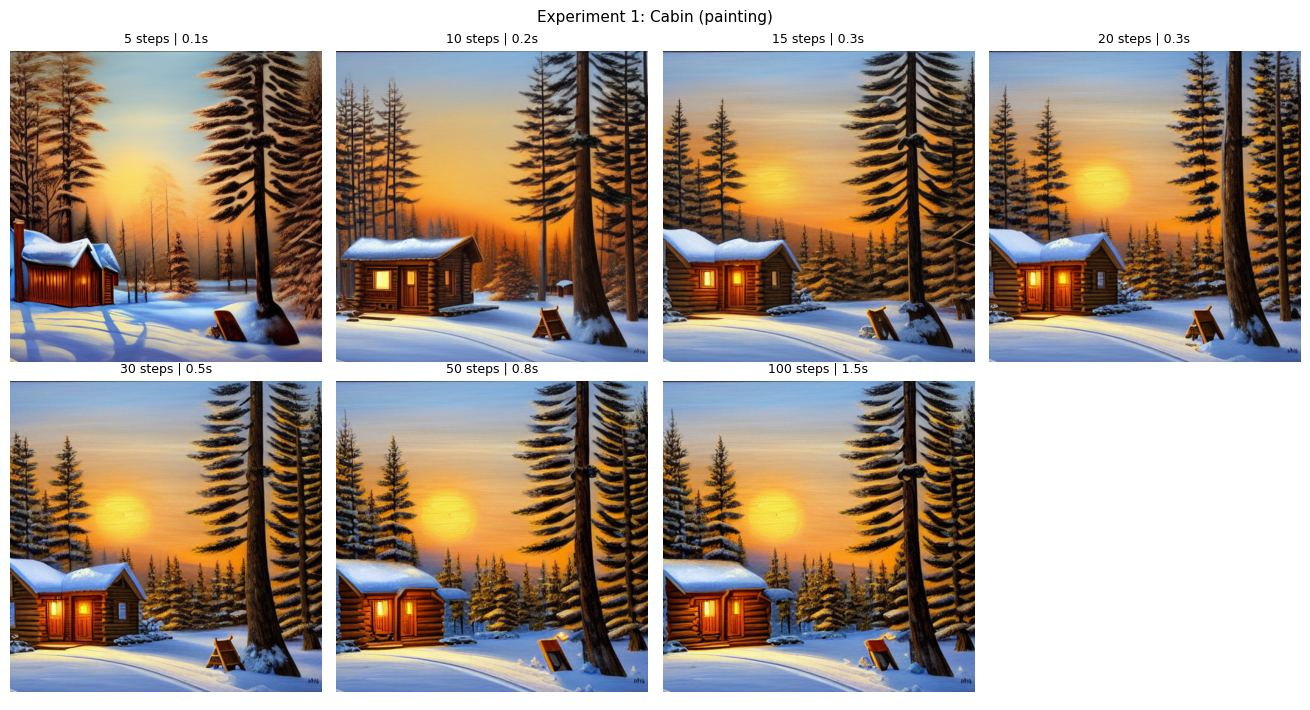

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

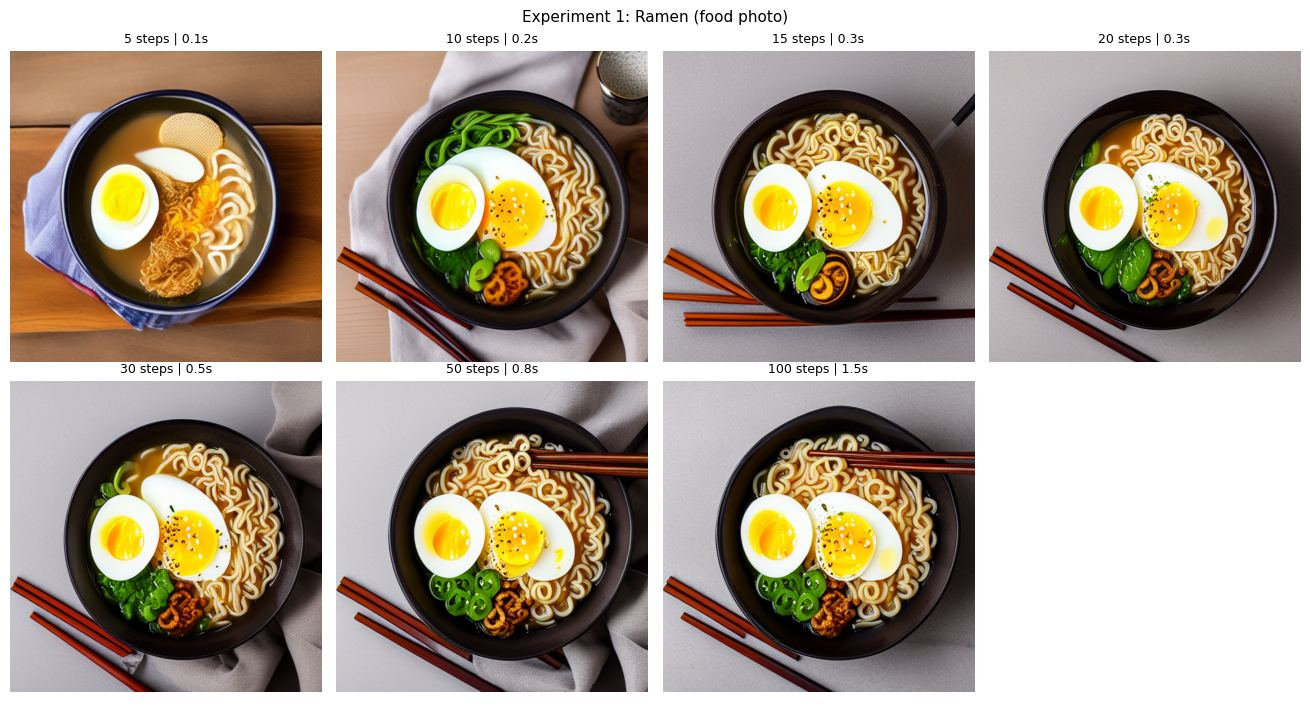

In [ ]:

STEPS = [5, 10, 15, 20, 30, 50, 100]

for p_idx, prompt in enumerate(PROMPTS):

    # Generate reference image using 100 steps
    ref, dt_ref = generate(
        prompt,
        steps=100,
        guidance=7.5,
        sampler="DPM++ 2M"
    )

    store[("ref", p_idx)] = ref

    imgs, titles = [], []

    for s in STEPS:

        if s == 100:
            img, dt, r = ref, dt_ref, None

        else:
            (img, dt), r = generate(
                prompt,
                steps=s,
                guidance=7.5,
                sampler="DPM++ 2M"
            ), ref

        # Calculate and store evaluation metrics
        record(
            "steps", p_idx, s, 7.5,
            "DPM++ 2M", img, dt, r
        )

        imgs.append(img)
        titles.append(f"{s} steps | {dt:.1f}s")

    # Display generated images
    grid(
        imgs,
        titles,
        4,
        f"{OUT}/exp1_steps_p{p_idx}.png",
        f"Experiment 1: {PNAMES[p_idx]}"
    )


### 7.1 Zoomed detail and difference maps

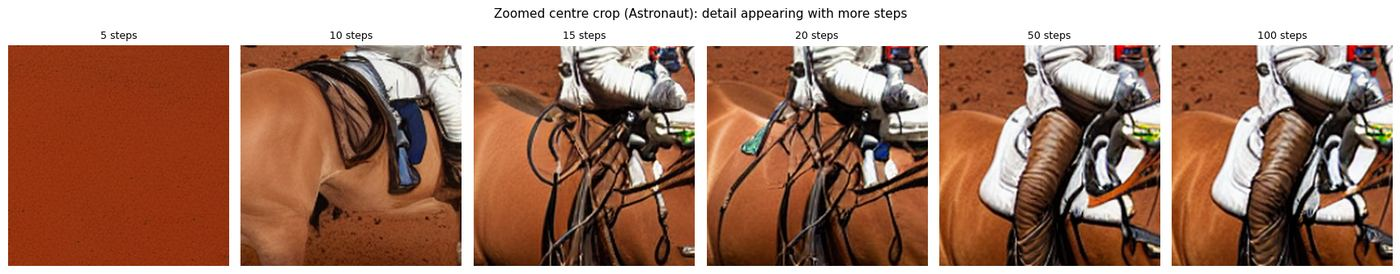

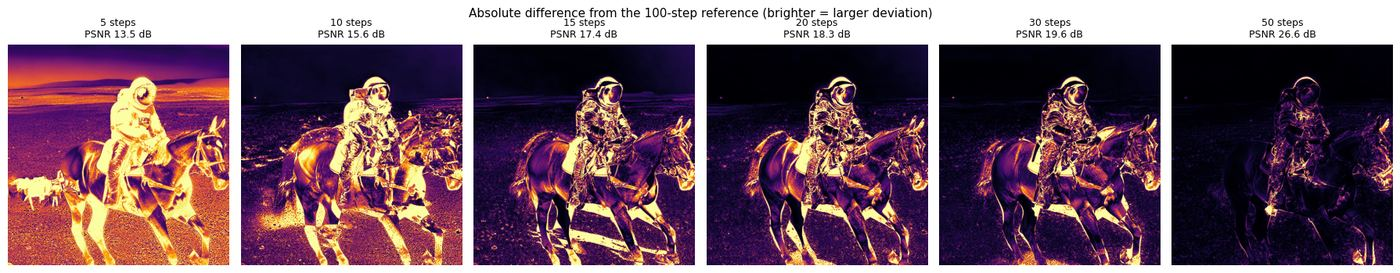

In [ ]:
box = (176, 176, 336, 336)
items = [(store[("steps", 0, s, 7.5, "DPM++ 2M")], f"{s} steps") for s in [5, 10, 15, 20, 50, 100]]
crop_row(items, box, f"{OUT}/exp1_zoom.png", "Zoomed centre crop (Astronaut): detail appearing with more steps")

ref0 = np.asarray(store[("ref", 0)], np.float32)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, s in zip(axes, [5, 10, 15, 20, 30, 50]):
    im0 = np.asarray(store[("steps", 0, s, 7.5, "DPM++ 2M")], np.float32)
    d = np.abs(im0 - ref0).mean(axis=2)
    h = ax.imshow(d, cmap="inferno", vmin=0, vmax=60); ax.axis("off")
    ax.set_title(f"{s} steps\nPSNR {psnr(im0, ref0):.1f} dB", fontsize=9)
fig.suptitle("Absolute difference from the 100-step reference (brighter = larger deviation)", fontsize=11)
plt.tight_layout(); fig.savefig(f"{OUT}/exp1_diffmaps.png", dpi=120); plt.show()

### 7.2 Quantitative results: steps

,CLIP,PSNR vs ref (dB),Sharpness,Contrast,Saturation %,Time (s)
steps,,,,,,
5,34.00,12.99,758.65,49.22,62.21,0.12
10,36.10,15.21,796.90,56.16,51.29,0.19
15,36.55,17.15,834.27,57.22,49.03,0.27
20,36.56,17.62,946.67,58.16,49.20,0.34
30,36.37,18.20,933.08,60.07,49.64,0.49
50,36.40,24.18,988.46,62.60,49.70,0.79
100,36.46,NaN,924.82,61.78,49.35,1.54


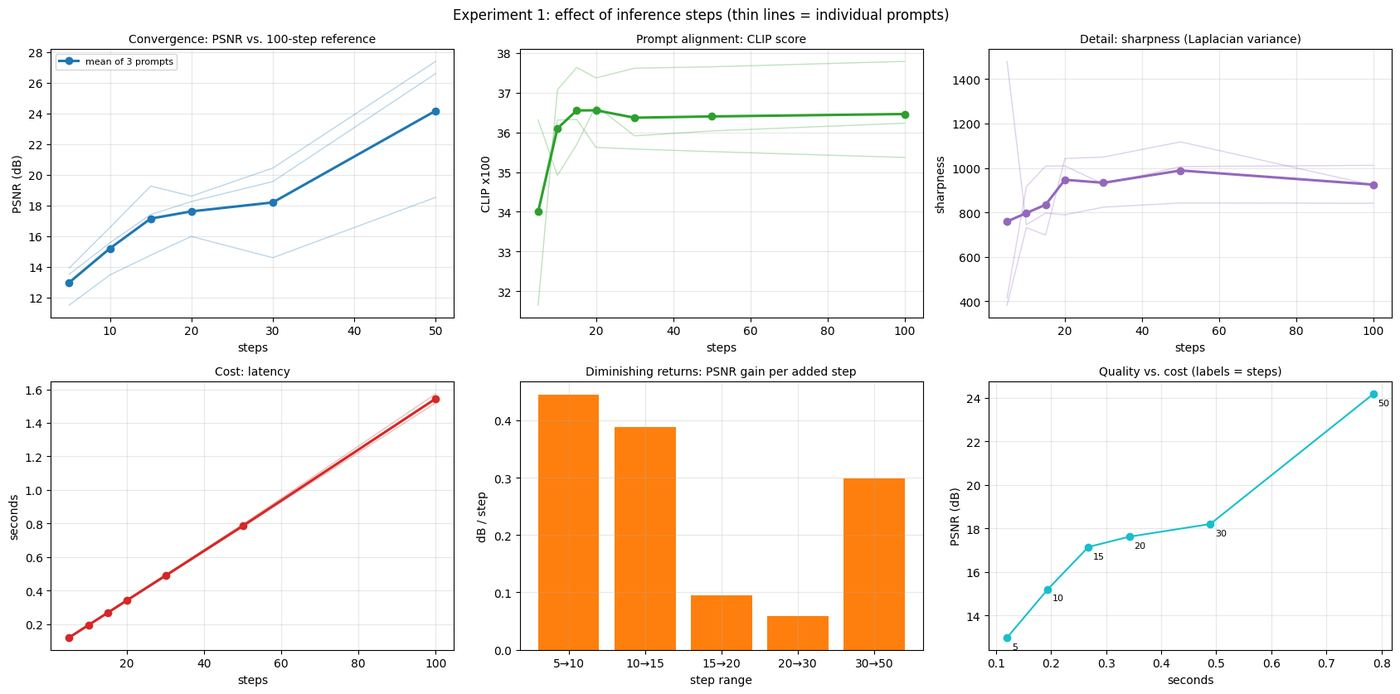

In [ ]:
df = pd.DataFrame(rows)
d1 = df[df.exp == "steps"]
steps_t = d1.groupby("steps")[["cs", "psnr_vs_ref", "sharp", "contrast", "sat", "time_s"]].mean()
display(steps_t.round(2).rename(columns={"psnr_vs_ref": "PSNR vs ref (dB)", "cs": "CLIP", "sharp": "Sharpness",
                                         "contrast": "Contrast", "sat": "Saturation %", "time_s": "Time (s)"}))

fig, ax = plt.subplots(2, 3, figsize=(17, 8.5))
line_panel(ax[0, 0], d1, "steps", "psnr_vs_ref", "Convergence: PSNR vs. 100-step reference", "PSNR (dB)", "tab:blue")
line_panel(ax[0, 1], d1, "steps", "cs", "Prompt alignment: CLIP score", "CLIP x100", "tab:green")
line_panel(ax[0, 2], d1, "steps", "sharp", "Detail: sharpness (Laplacian variance)", "sharpness", "tab:purple")
line_panel(ax[1, 0], d1, "steps", "time_s", "Cost: latency", "seconds", "tab:red")
ps = steps_t.psnr_vs_ref.dropna()
gain = ps.diff().dropna() / pd.Series(ps.index, index=ps.index).diff().dropna()
ax[1, 1].bar([f"{a}→{b}" for a, b in zip(ps.index[:-1], ps.index[1:])], gain.values, color="tab:orange")
ax[1, 1].set_title("Diminishing returns: PSNR gain per added step", fontsize=10); ax[1, 1].set_ylabel("dB / step"); ax[1, 1].set_xlabel("step range")
ax[1, 2].plot(steps_t.time_s.drop(100), ps.values, marker="o", color="tab:cyan")
for s_, t_, p_ in zip(ps.index, steps_t.time_s.drop(100), ps.values): ax[1, 2].annotate(str(s_), (t_, p_), textcoords="offset points", xytext=(4, -10), fontsize=8)
ax[1, 2].set_title("Quality vs. cost (labels = steps)", fontsize=10); ax[1, 2].set_xlabel("seconds"); ax[1, 2].set_ylabel("PSNR (dB)")
ax[0, 0].legend(fontsize=8); fig.suptitle("Experiment 1: effect of inference steps (thin lines = individual prompts)", fontsize=12)
plt.tight_layout(); fig.savefig(f"{OUT}/exp1_summary.png", dpi=120); plt.show()

## 8. Experiment 2: Effect of Guidance Scale
**Fixed:** steps = 30, sampler = DPM++ 2M. **Varied:** guidance = 1, 3, 5, 7.5, 10, 15, 20, 30.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

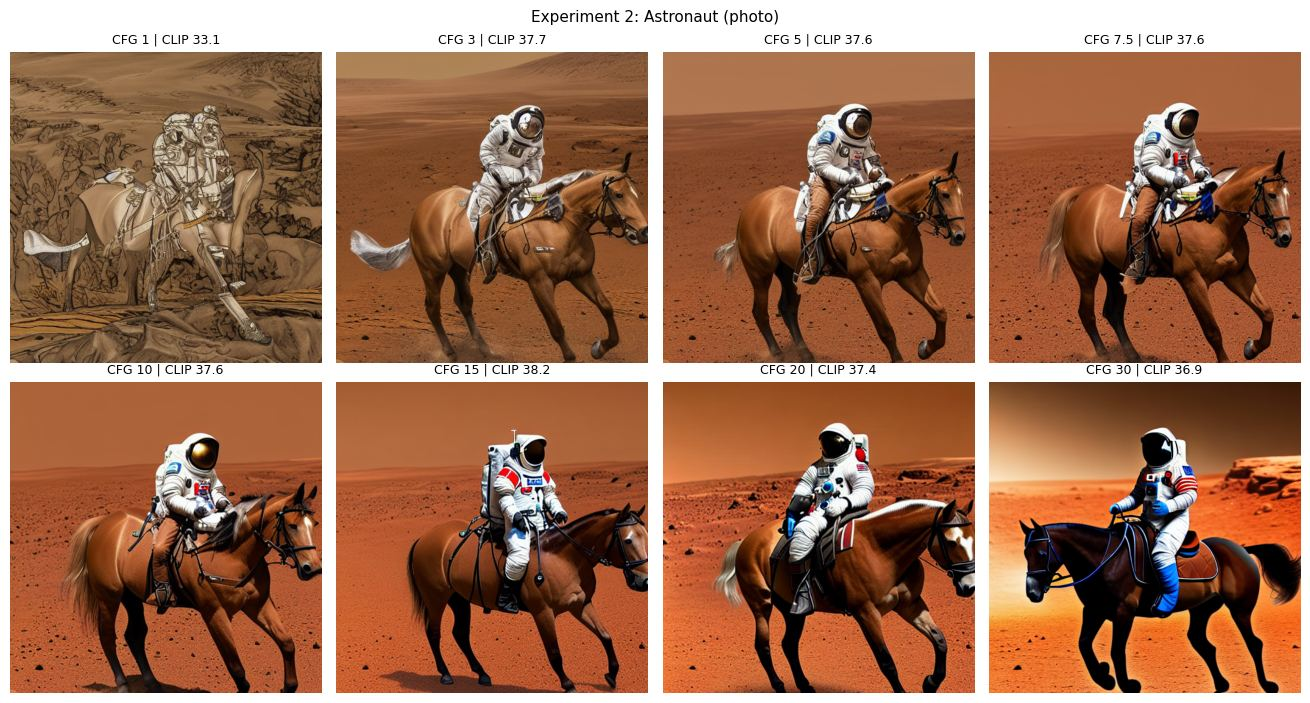

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

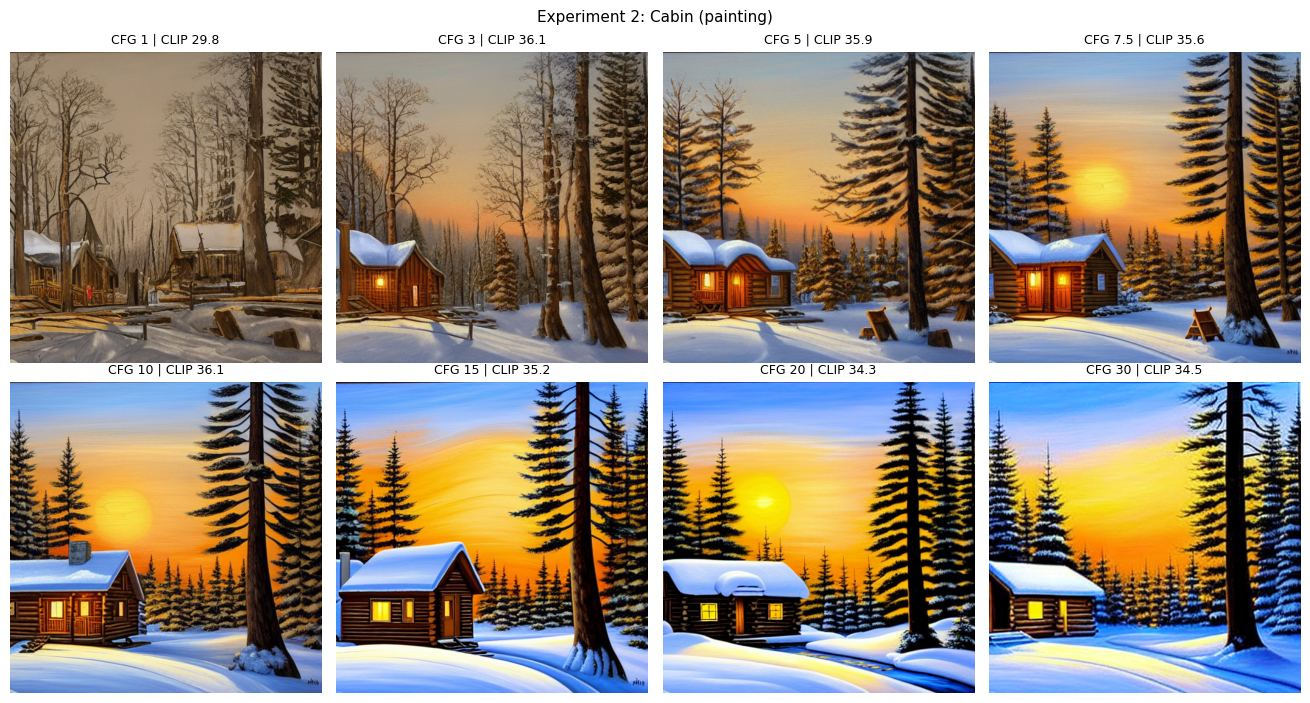

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

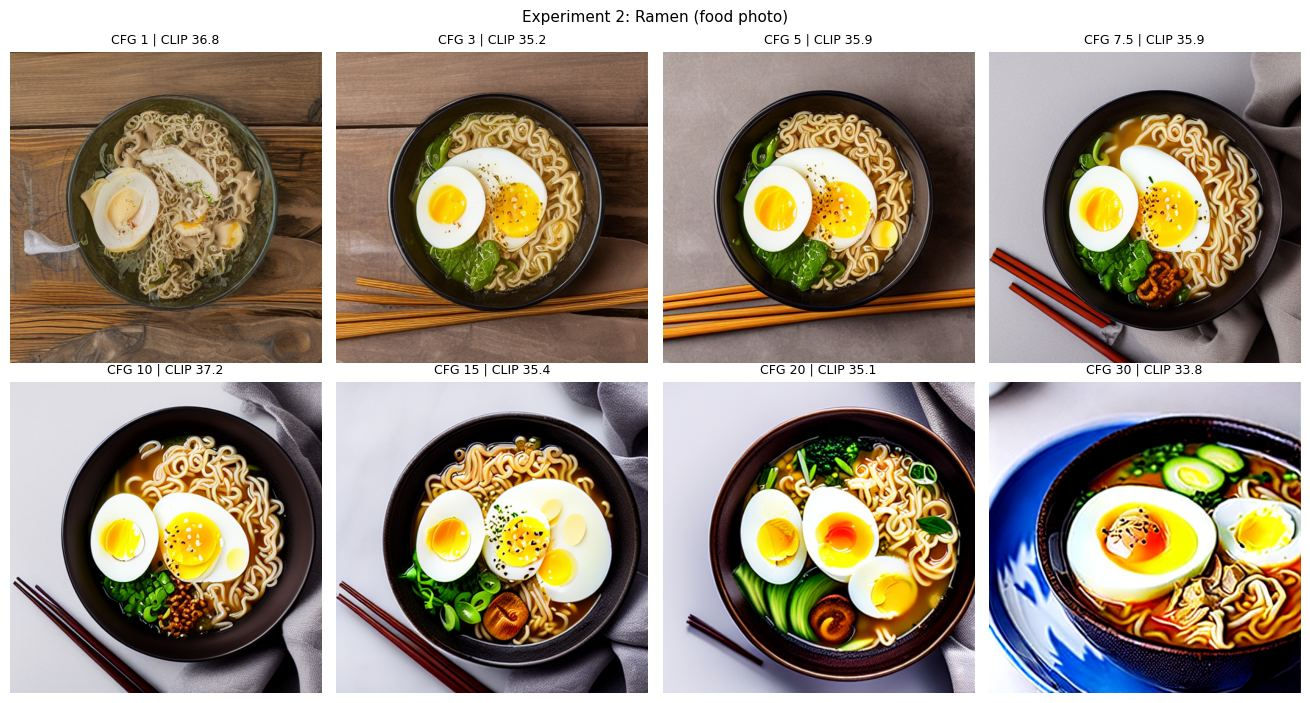

In [ ]:
GUIDANCE = [1, 3, 5, 7.5, 10, 15, 20, 30]
for p_idx, prompt in enumerate(PROMPTS):
    imgs, titles = [], []
    for gs in GUIDANCE:
        img, dt = generate(prompt, steps=30, guidance=gs, sampler="DPM++ 2M")
        record("guidance", p_idx, 30, gs, "DPM++ 2M", img, dt)
        imgs.append(img); titles.append(f"CFG {gs} | CLIP {rows[-1]['cs']:.1f}")
    grid(imgs, titles, 4, f"{OUT}/exp2_guidance_p{p_idx}.png", f"Experiment 2: {PNAMES[p_idx]}")

### 8.1 Zoomed comparison and quantitative results

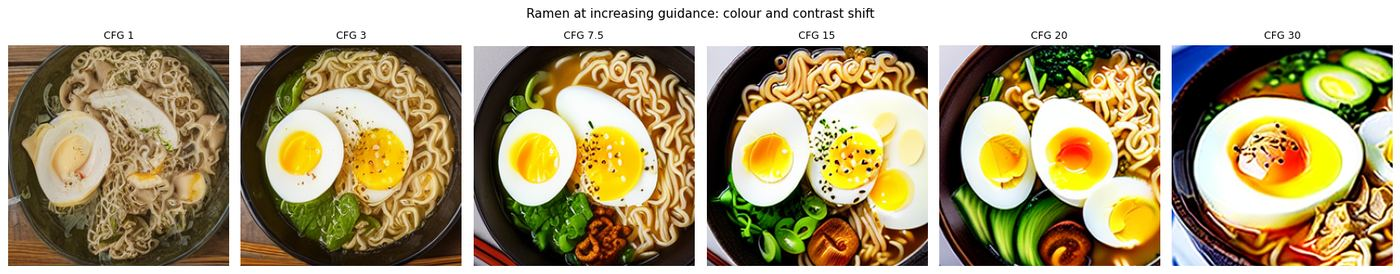

,CLIP,Saturation %,Contrast,Sharpness
guidance,,,,
1.0,33.25,44.93,38.49,1573.89
3.0,36.34,49.89,46.48,1036.18
5.0,36.46,48.74,53.69,889.86
7.5,36.37,49.64,60.07,933.08
10.0,36.93,51.17,66.83,1052.62
15.0,36.27,54.23,70.15,1035.15
20.0,35.62,57.76,73.71,908.04
30.0,35.05,58.57,76.69,701.96


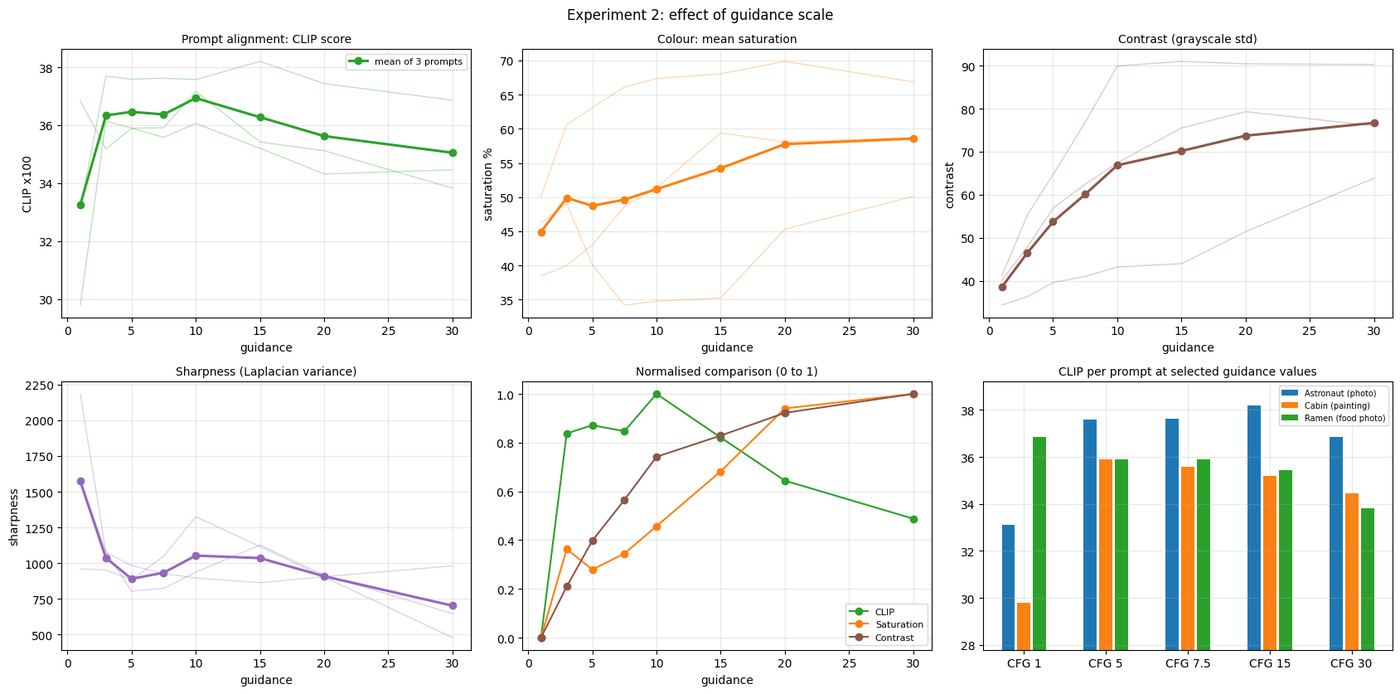

In [ ]:
items = [(store[("guidance", 2, 30, gs, "DPM++ 2M")], f"CFG {gs}") for gs in [1, 3, 7.5, 15, 20, 30]]
crop_row(items, (96, 96, 416, 416), f"{OUT}/exp2_zoom.png", "Ramen at increasing guidance: colour and contrast shift", size=256)

df = pd.DataFrame(rows)
d2 = df[df.exp == "guidance"]
guid_t = d2.groupby("guidance")[["cs", "sat", "contrast", "sharp"]].mean()
display(guid_t.round(2).rename(columns={"cs": "CLIP", "sat": "Saturation %", "contrast": "Contrast", "sharp": "Sharpness"}))

fig, ax = plt.subplots(2, 3, figsize=(17, 8.5))
line_panel(ax[0, 0], d2, "guidance", "cs", "Prompt alignment: CLIP score", "CLIP x100", "tab:green")
line_panel(ax[0, 1], d2, "guidance", "sat", "Colour: mean saturation", "saturation %", "tab:orange")
line_panel(ax[0, 2], d2, "guidance", "contrast", "Contrast (grayscale std)", "contrast", "tab:brown")
line_panel(ax[1, 0], d2, "guidance", "sharp", "Sharpness (Laplacian variance)", "sharpness", "tab:purple")
norm = (guid_t - guid_t.min()) / (guid_t.max() - guid_t.min() + 1e-9)
for c, col in zip(["cs", "sat", "contrast"], ["tab:green", "tab:orange", "tab:brown"]):
    ax[1, 1].plot(norm.index, norm[c], marker="o", label={"cs": "CLIP", "sat": "Saturation", "contrast": "Contrast"}[c], color=col)
ax[1, 1].set_title("Normalised comparison (0 to 1)", fontsize=10); ax[1, 1].set_xlabel("guidance"); ax[1, 1].legend(fontsize=8)
sel = [1, 5, 7.5, 15, 30]; w = .16
for k, p in enumerate(range(3)):
    vals = [d2[(d2.prompt == p) & (d2.guidance == gs)].cs.values[0] for gs in sel]
    ax[1, 2].bar(np.arange(len(sel)) + (k - 1) * w * 1.2, vals, width=w, label=PNAMES[p])
ax[1, 2].set_xticks(range(len(sel))); ax[1, 2].set_xticklabels([f"CFG {s}" for s in sel])
ax[1, 2].set_ylim(min(d2.cs) - 2, max(d2.cs) + 1); ax[1, 2].set_title("CLIP per prompt at selected guidance values", fontsize=10); ax[1, 2].legend(fontsize=7)
ax[0, 0].legend(fontsize=8); fig.suptitle("Experiment 2: effect of guidance scale", fontsize=12)
plt.tight_layout(); fig.savefig(f"{OUT}/exp2_summary.png", dpi=120); plt.show()

## 9. Experiment 3: Comparison of Sampling Methods
**Fixed:** guidance = 7.5. **Varied:** 9 samplers at 10, 20 and 50 steps. Convergence is measured against the 100-step DPM++ 2M reference from Experiment 1.

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

... (17 outputs left out)

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

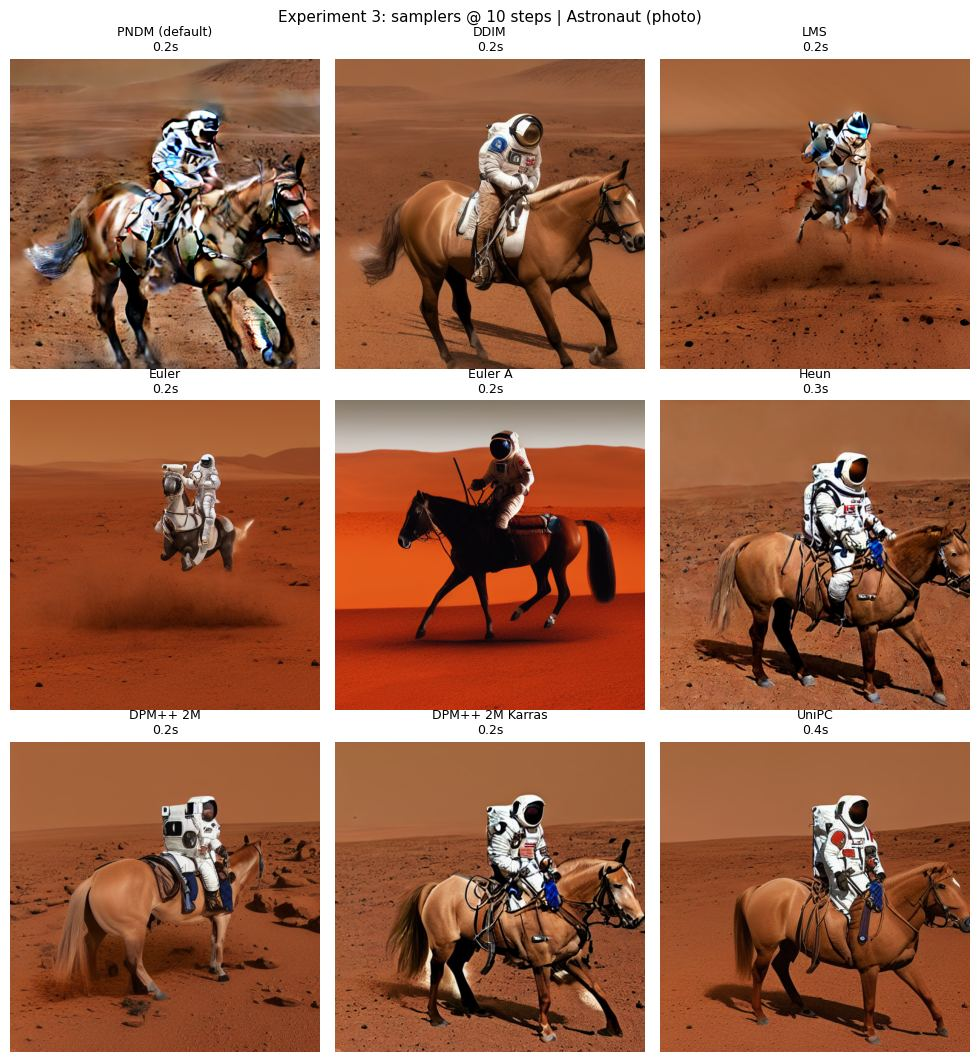

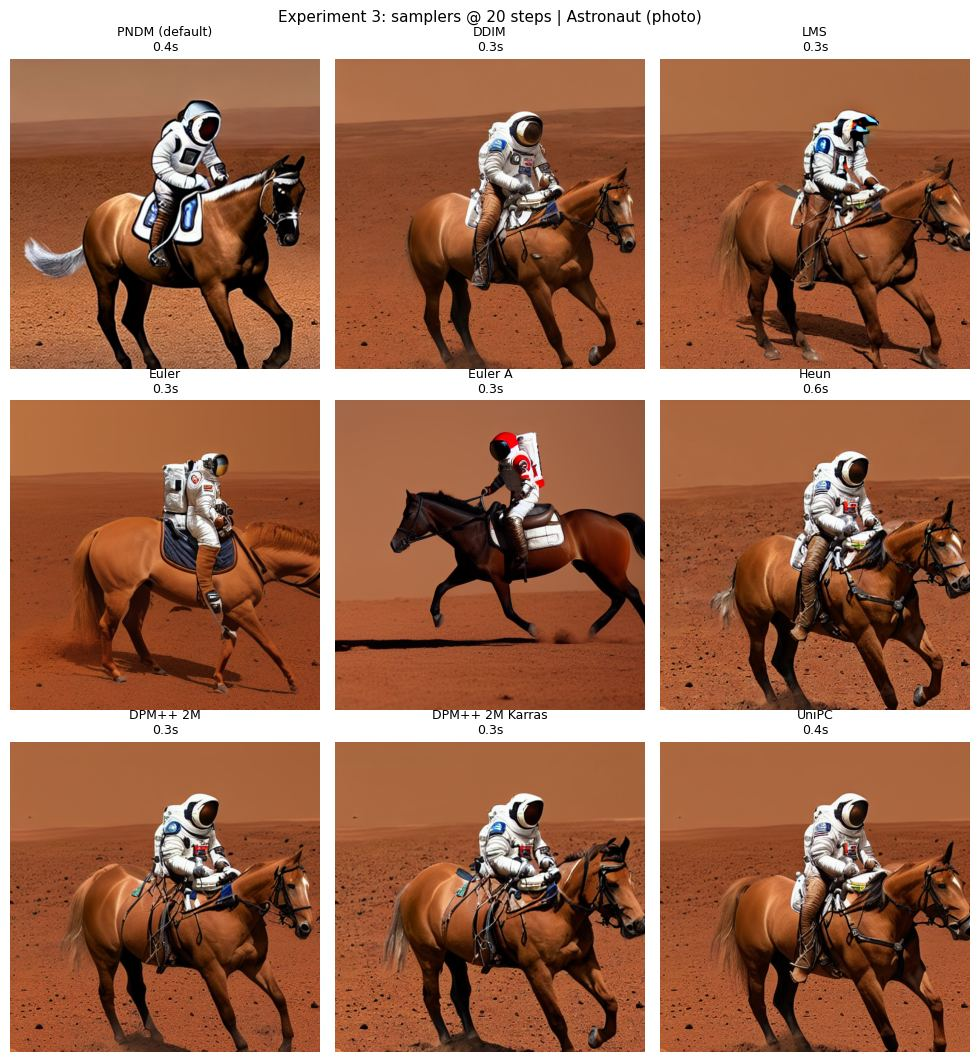

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

... (17 outputs left out)

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

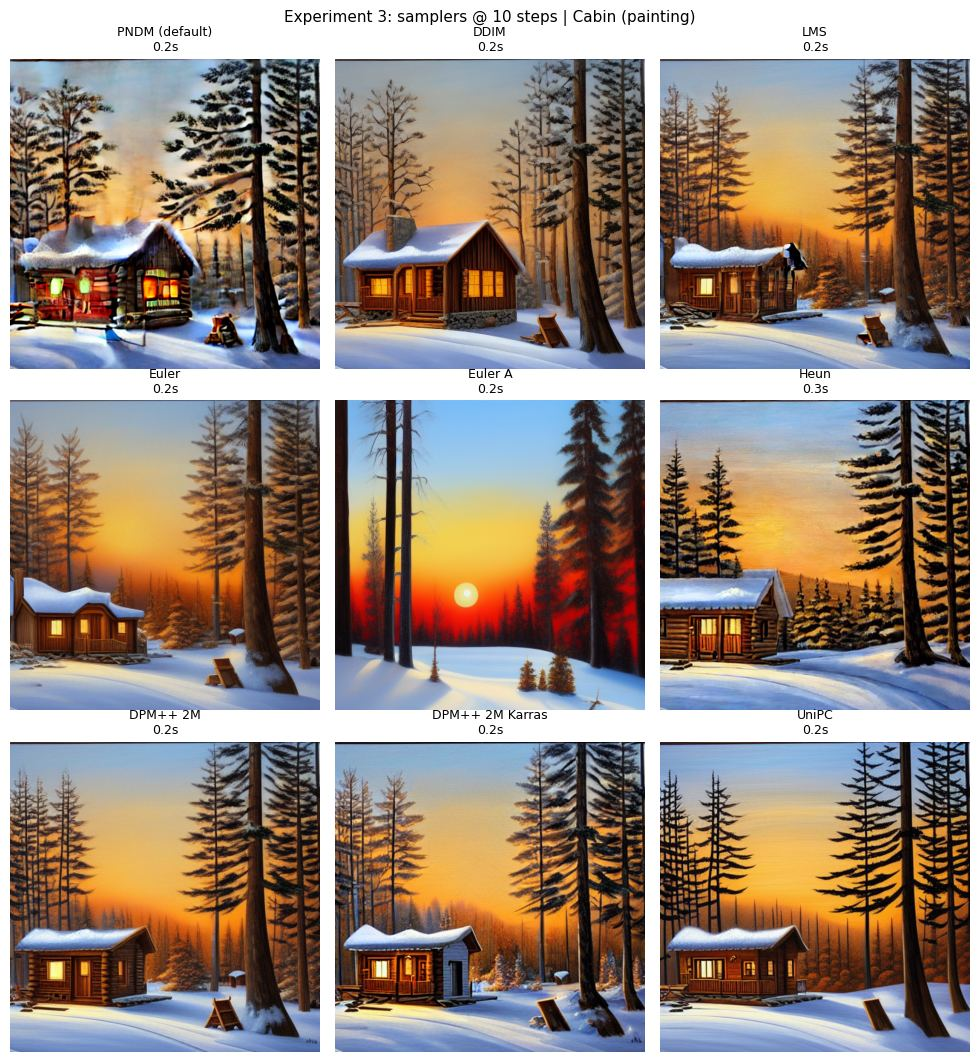

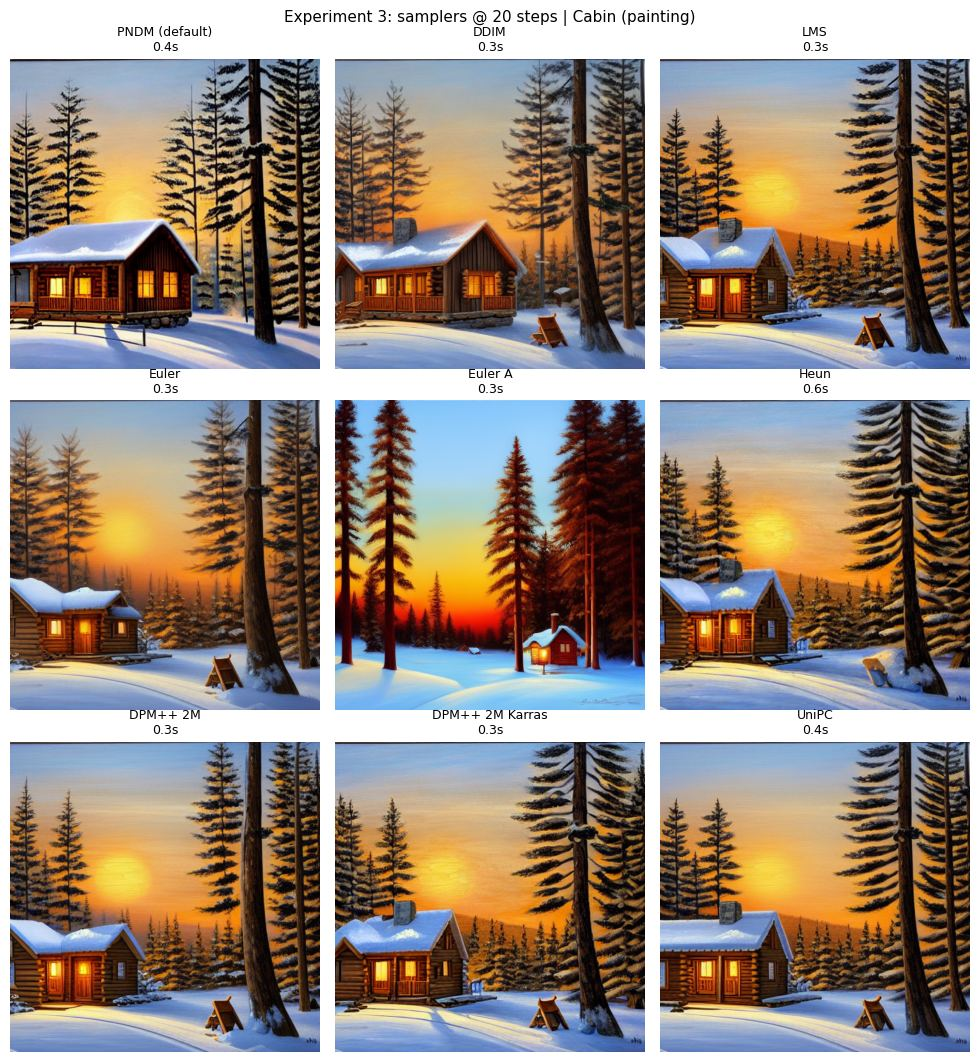

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

... (17 outputs left out)

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

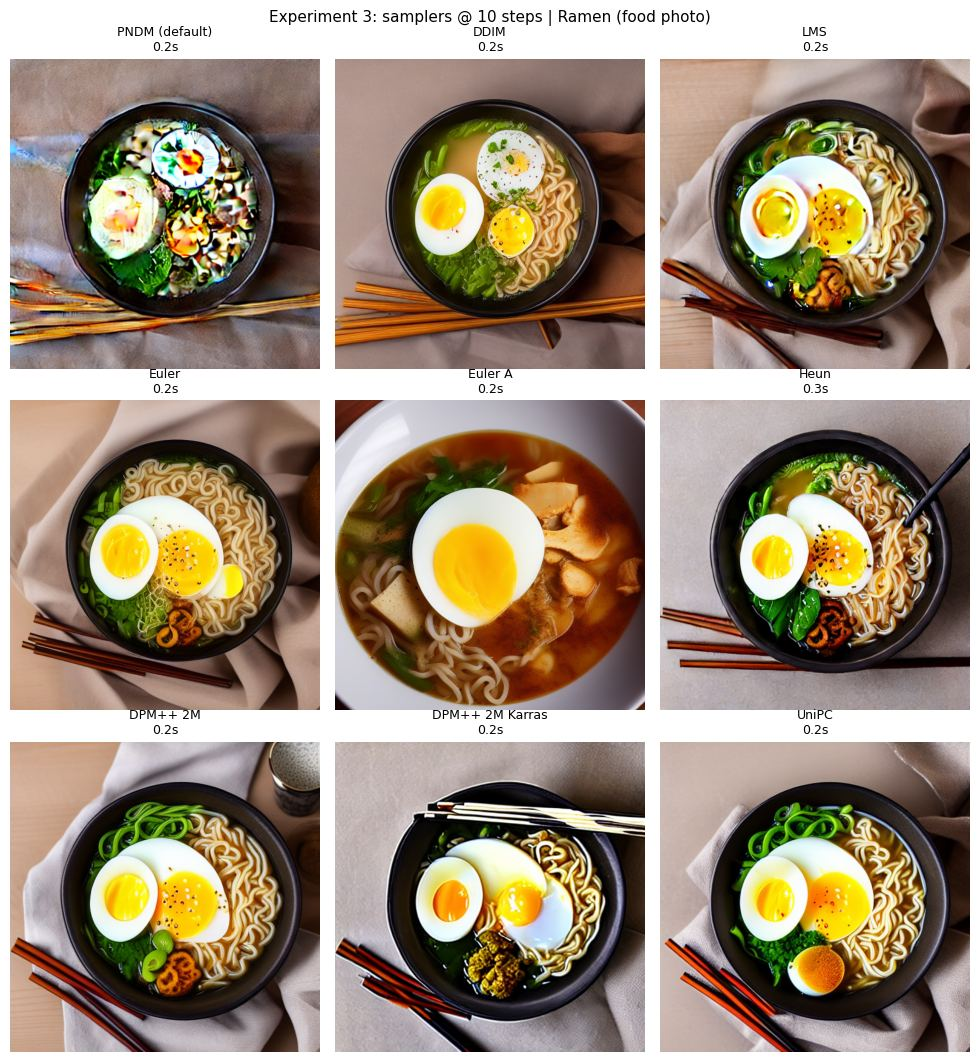

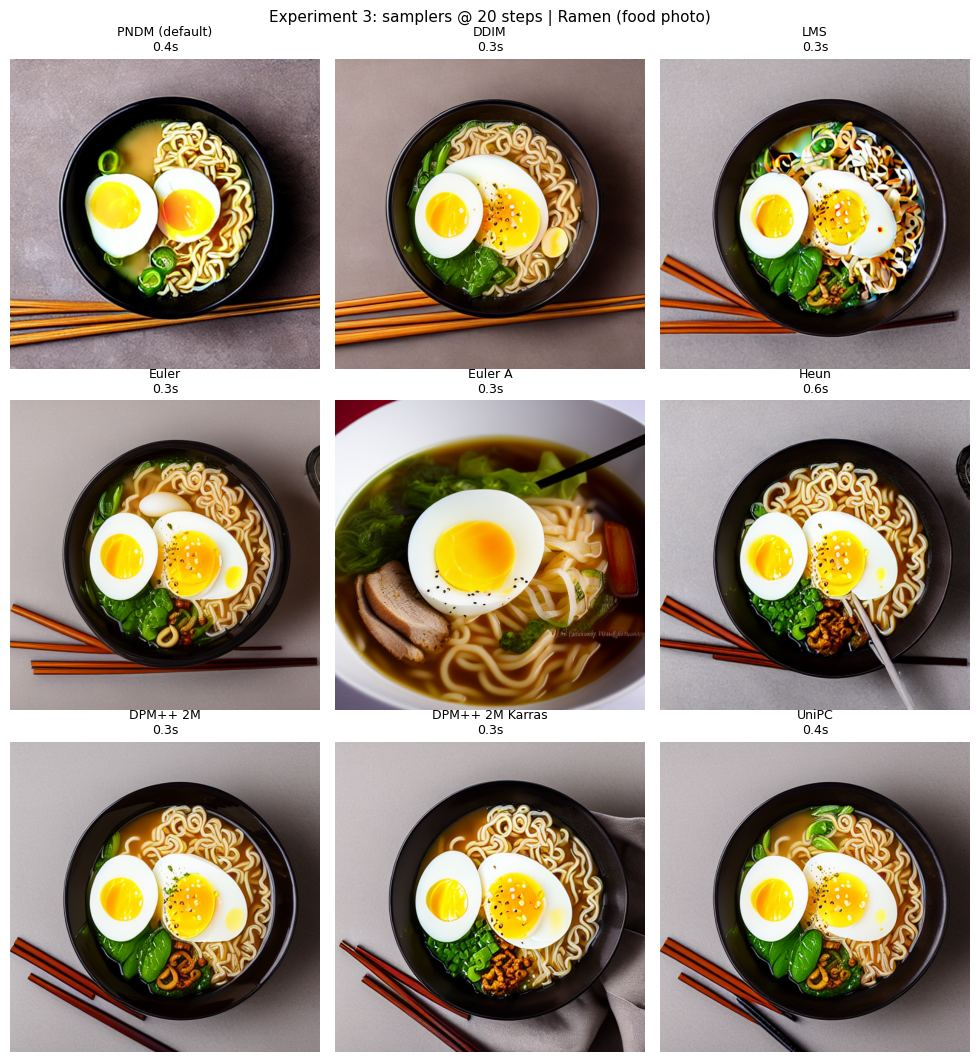

In [ ]:
SAMP_STEPS = [10, 20, 50]
for p_idx, prompt in enumerate(PROMPTS):
    ref = store[("ref", p_idx)]
    for name in ORDER:
        for s in SAMP_STEPS:
            img, dt = generate(prompt, steps=s, guidance=7.5, sampler=name)
            record("sampler", p_idx, s, 7.5, name, img, dt, ref)
    for s in [10, 20]:
        imgs = [store[("sampler", p_idx, s, 7.5, n)] for n in ORDER]
        titles = [f"{n}\n{rows[[(r['sampler'], r['steps'], r['prompt']) for r in rows].index((n, s, p_idx))]['time_s']:.1f}s" for n in ORDER]
        grid(imgs, titles, 3, f"{OUT}/exp3_samplers{s}_p{p_idx}.png", f"Experiment 3: samplers @ {s} steps | {PNAMES[p_idx]}")

### 9.1 Zoomed side-by-side comparison of samplers (10 steps)

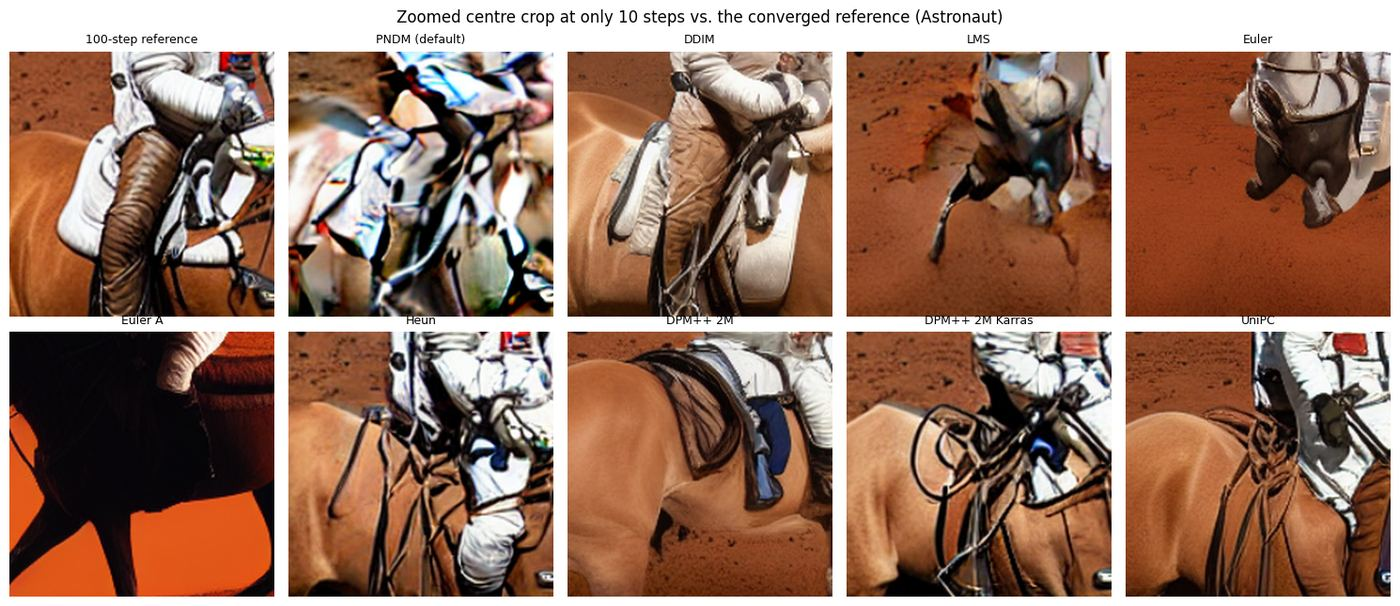

In [ ]:
items = [(store[("ref", 0)], "100-step reference")] + [(store[("sampler", 0, 10, 7.5, n)], n) for n in ORDER]
fig, axes = plt.subplots(2, 5, figsize=(15, 6.6))
for ax, (im, lab) in zip(axes.ravel(), items):
    ax.imshow(im.crop((176, 176, 336, 336)).resize((256, 256), Image.LANCZOS)); ax.axis("off"); ax.set_title(lab, fontsize=9)
fig.suptitle("Zoomed centre crop at only 10 steps vs. the converged reference (Astronaut)", fontsize=12)
plt.tight_layout(); fig.savefig(f"{OUT}/exp3_zoom10.png", dpi=120); plt.show()

### 9.2 Quantitative comparison of samplers

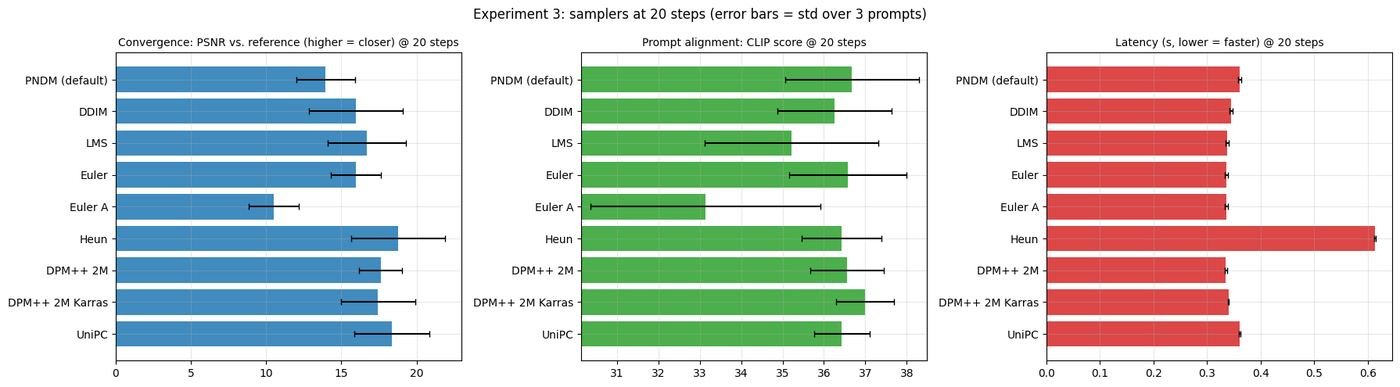

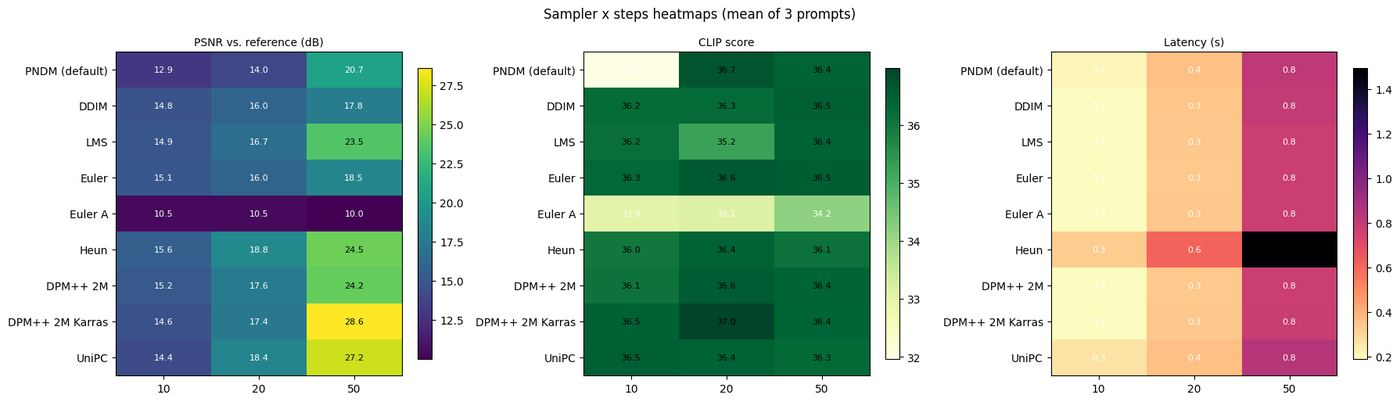

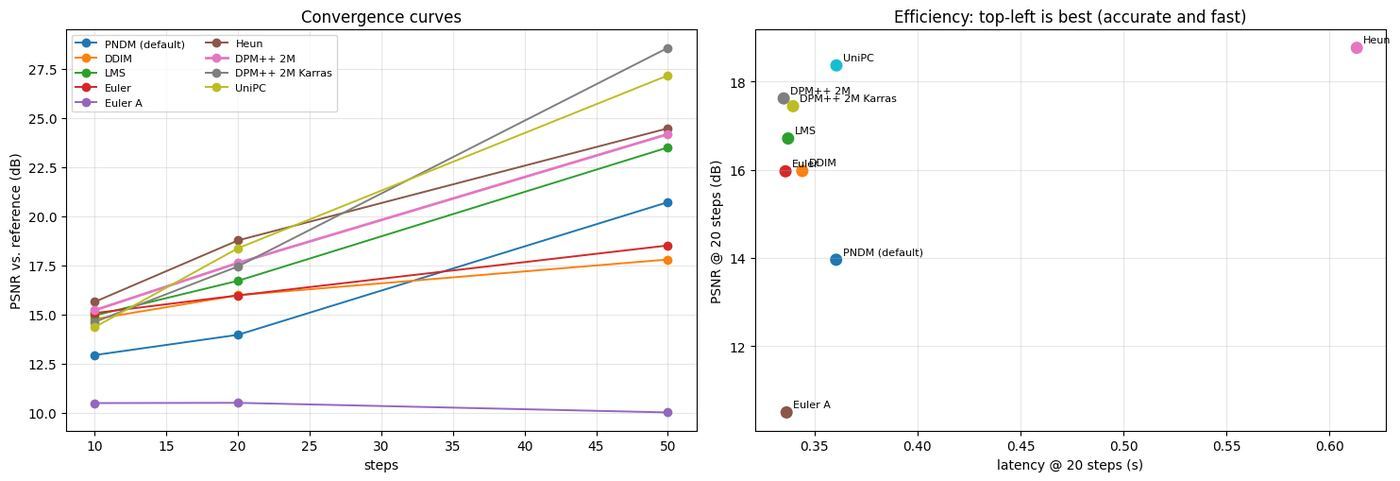

,PSNR@10 (dB),PSNR@20 (dB),CLIP@20,Time@20 (s),Mean rank (lower = better)
sampler,,,,,
DPM++ 2M,15.210000,17.620000,36.560000,0.340000,2.500000
Euler,15.070000,15.970000,36.580000,0.340000,3.750000
DPM++ 2M Karras,14.610000,17.440000,36.980000,0.340000,4.000000
Heun,15.640000,18.770000,36.430000,0.610000,4.250000
LMS,14.950000,16.710000,35.220000,0.340000,5.250000
UniPC,14.350000,18.370000,36.430000,0.360000,5.500000
DDIM,14.760000,15.970000,36.260000,0.340000,6.000000
PNDM (default),12.930000,13.960000,36.680000,0.360000,6.250000
Euler A,10.480000,10.490000,33.140000,0.340000,7.500000


In [ ]:
df = pd.DataFrame(rows)
d3 = df[df.exp == "sampler"]

def at(steps, col): return d3[d3.steps == steps].groupby("sampler")[col].mean().reindex(ORDER)
def sd(steps, col): return d3[d3.steps == steps].groupby("sampler")[col].std().reindex(ORDER)

# --- bar charts at 20 steps
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (col, ttl, c) in zip(ax, [("psnr_vs_ref", "Convergence: PSNR vs. reference (higher = closer)", "tab:blue"),
                                  ("cs", "Prompt alignment: CLIP score", "tab:green"),
                                  ("time_s", "Latency (s, lower = faster)", "tab:red")]):
    m, e = at(20, col), sd(20, col)
    a.barh(ORDER, m.values, xerr=e.values, color=c, alpha=.85, capsize=3); a.invert_yaxis(); a.set_title(ttl + " @ 20 steps", fontsize=10)
    if col == "cs": a.set_xlim(m.min() - 3, m.max() + 1.5)
fig.suptitle("Experiment 3: samplers at 20 steps (error bars = std over 3 prompts)", fontsize=12)
plt.tight_layout(); fig.savefig(f"{OUT}/exp3_bars20.png", dpi=120); plt.show()

# --- heatmaps sampler x steps
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
heat(ax[0], d3.pivot_table(index="sampler", columns="steps", values="psnr_vs_ref").reindex(ORDER), "PSNR vs. reference (dB)")
heat(ax[1], d3.pivot_table(index="sampler", columns="steps", values="cs").reindex(ORDER), "CLIP score", cmap="YlGn")
heat(ax[2], d3.pivot_table(index="sampler", columns="steps", values="time_s").reindex(ORDER), "Latency (s)", fmt="{:.1f}", cmap="magma_r")
fig.suptitle("Sampler x steps heatmaps (mean of 3 prompts)", fontsize=12)
plt.tight_layout(); fig.savefig(f"{OUT}/exp3_heatmaps.png", dpi=120); plt.show()

# --- convergence curves and efficiency
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
for name in ORDER:
    m = d3[d3.sampler == name].groupby("steps")["psnr_vs_ref"].mean()
    ax[0].plot(m.index, m.values, marker="o", label=name, lw=2 if "DPM++ 2M" == name else 1.4)
ax[0].set_xlabel("steps"); ax[0].set_ylabel("PSNR vs. reference (dB)"); ax[0].set_title("Convergence curves"); ax[0].legend(fontsize=8, ncol=2)
p20, t20 = at(20, "psnr_vs_ref"), at(20, "time_s")
ax[1].scatter(t20, p20, s=70, c=range(len(ORDER)), cmap="tab10")
for n_ in ORDER: ax[1].annotate(n_, (t20[n_], p20[n_]), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax[1].set_xlabel("latency @ 20 steps (s)"); ax[1].set_ylabel("PSNR @ 20 steps (dB)")
ax[1].set_title("Efficiency: top-left is best (accurate and fast)")
plt.tight_layout(); fig.savefig(f"{OUT}/exp3_convergence_efficiency.png", dpi=120); plt.show()

# --- composite ranking table
r = pd.DataFrame({"PSNR@10 (dB)": at(10, "psnr_vs_ref"), "PSNR@20 (dB)": at(20, "psnr_vs_ref"), "CLIP@20": at(20, "cs"),
                  "Time@20 (s)": at(20, "time_s")})
rank = pd.DataFrame({"PSNR@10 (dB)": r.iloc[:, 0].rank(ascending=False), "PSNR@20 (dB)": r.iloc[:, 1].rank(ascending=False),
                     "CLIP@20": r.iloc[:, 2].rank(ascending=False), "Time@20 (s)": r.iloc[:, 3].rank(ascending=True)})
r["Mean rank (lower = better)"] = rank.mean(axis=1)
ranking = r.sort_values("Mean rank (lower = better)")
try: display(ranking.round(2).style.background_gradient(cmap="RdYlGn_r", subset=["Mean rank (lower = better)"]))
except Exception: display(ranking.round(2))
ranking.round(3).to_csv(f"{OUT}/sampler_ranking.csv")

## 10. Experiment 4: Interaction between Steps and Guidance
One prompt (Cabin, painting) is rendered over a 4x4 grid of steps and guidance with DPM++ 2M.

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

... (6 outputs left out)

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

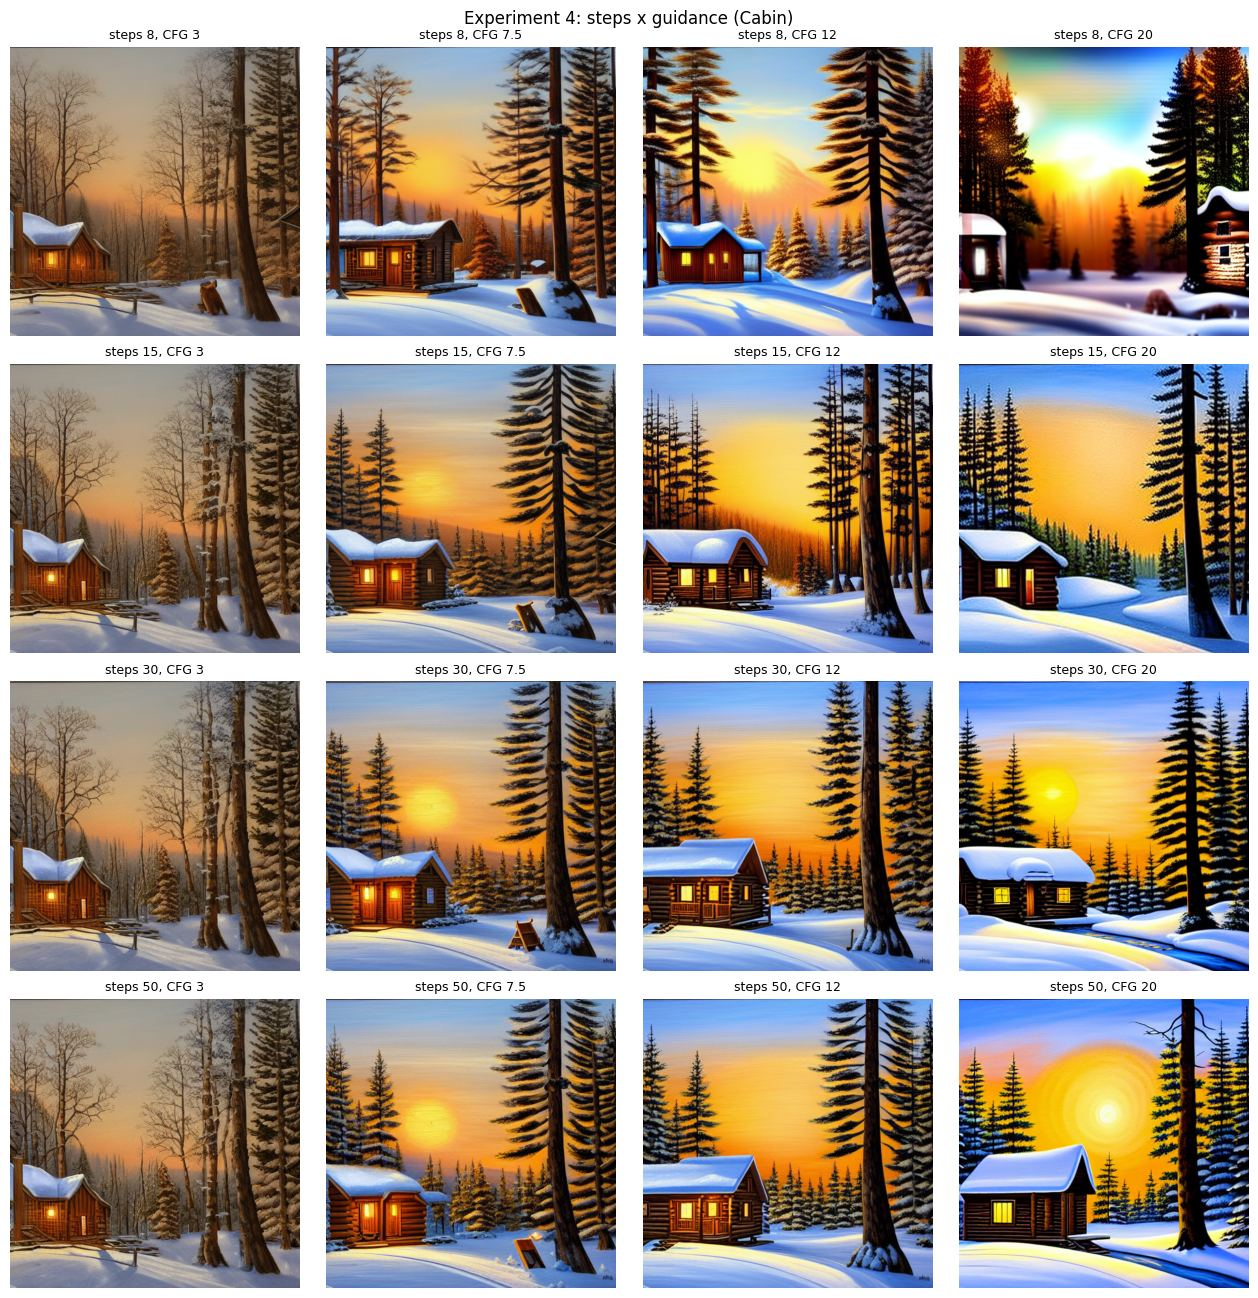

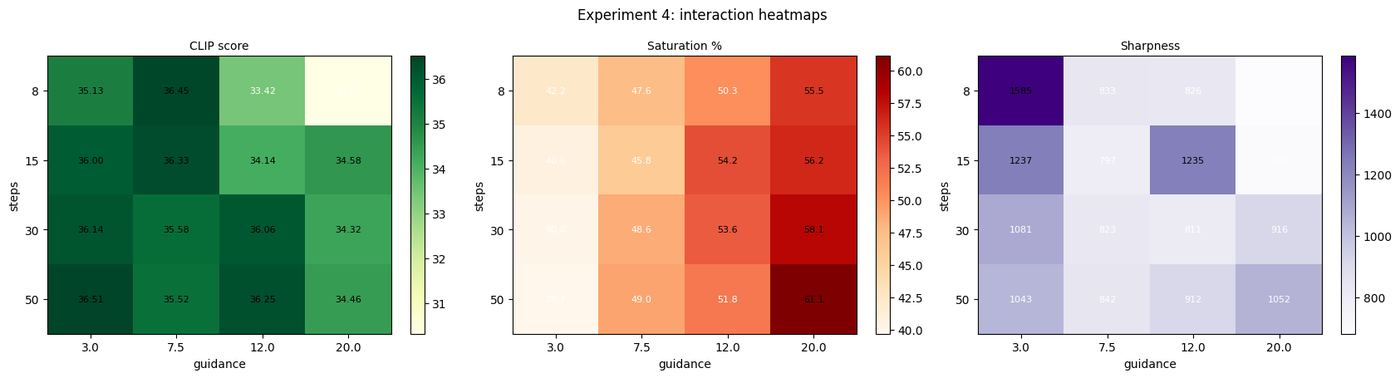

In [ ]:
S_LIST, G_LIST = [8, 15, 30, 50], [3, 7.5, 12, 20]
fig, axes = plt.subplots(len(S_LIST), len(G_LIST), figsize=(3.2 * len(G_LIST), 3.3 * len(S_LIST)))
for i, s in enumerate(S_LIST):
    for j, gs in enumerate(G_LIST):
        img, dt = generate(PROMPTS[1], steps=s, guidance=gs, sampler="DPM++ 2M")
        record("interaction", 1, s, gs, "DPM++ 2M", img, dt)
        axes[i, j].imshow(img); axes[i, j].axis("off"); axes[i, j].set_title(f"steps {s}, CFG {gs}", fontsize=9)
fig.suptitle("Experiment 4: steps x guidance (Cabin)", fontsize=12)
plt.tight_layout(); fig.savefig(f"{OUT}/exp4_interaction_grid.png", dpi=120); plt.show()

df = pd.DataFrame(rows); d4 = df[df.exp == "interaction"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
heat(ax[0], d4.pivot_table(index="steps", columns="guidance", values="cs"), "CLIP score", cmap="YlGn", fmt="{:.2f}")
heat(ax[1], d4.pivot_table(index="steps", columns="guidance", values="sat"), "Saturation %", cmap="OrRd")
heat(ax[2], d4.pivot_table(index="steps", columns="guidance", values="sharp"), "Sharpness", cmap="Purples", fmt="{:.0f}")
for a in ax: a.set_xlabel("guidance"); a.set_ylabel("steps")
fig.suptitle("Experiment 4: interaction heatmaps", fontsize=12)
plt.tight_layout(); fig.savefig(f"{OUT}/exp4_heatmaps.png", dpi=120); plt.show()

## 11. Consolidated Results

Total images generated and scored: 142


,images,mean_CLIP,mean_time_s
exp,,,
guidance,24,35.79,0.48
interaction,16,35.08,0.42
sampler,81,35.87,0.49
steps,21,36.06,0.53


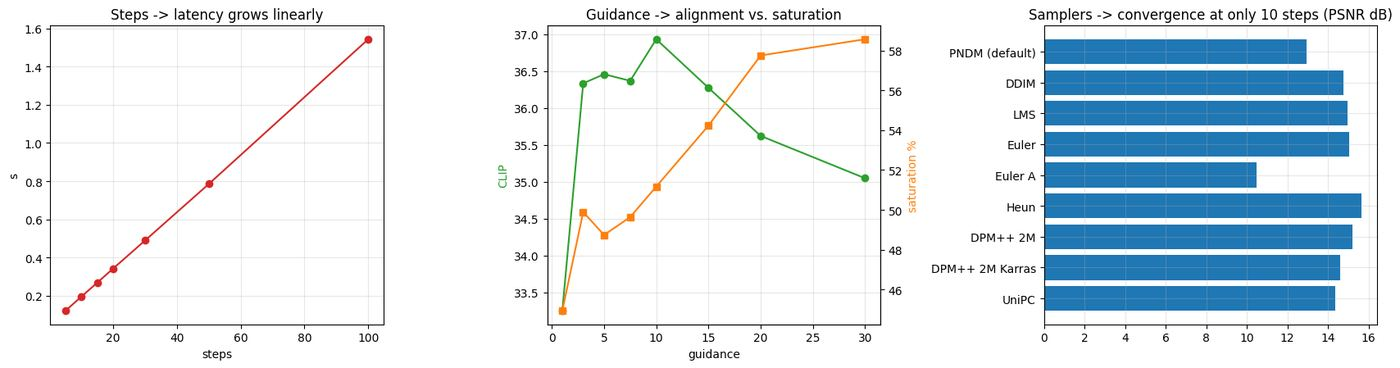

In [ ]:
df = pd.DataFrame(rows)
df.to_csv(f"{OUT}/results_all.csv", index=False)
print("Total images generated and scored:", len(df))
display(df.groupby("exp").agg(images=("cs", "size"), mean_CLIP=("cs", "mean"), mean_time_s=("time_s", "mean")).round(2))

# One-glance overview: the three "knobs" side by side
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
s_ = df[df.exp == "steps"].groupby("steps").time_s.mean()
ax[0].plot(s_.index, s_.values, marker="o", color="tab:red"); ax[0].set_title("Steps -> latency grows linearly"); ax[0].set_xlabel("steps"); ax[0].set_ylabel("s")
g_ = df[df.exp == "guidance"].groupby("guidance")[["cs", "sat"]].mean()
ax[1].plot(g_.index, g_.cs, marker="o", color="tab:green"); ax[1].set_ylabel("CLIP", color="tab:green"); ax[1].set_xlabel("guidance")
ax2 = ax[1].twinx(); ax2.plot(g_.index, g_.sat, marker="s", color="tab:orange"); ax2.set_ylabel("saturation %", color="tab:orange"); ax2.grid(False)
ax[1].set_title("Guidance -> alignment vs. saturation")
e_ = df[(df.exp == "sampler") & (df.steps == 10)].groupby("sampler").psnr_vs_ref.mean().reindex(ORDER)
ax[2].barh(ORDER, e_.values, color="tab:blue"); ax[2].invert_yaxis(); ax[2].set_title("Samplers -> convergence at only 10 steps (PSNR dB)")
plt.tight_layout(); fig.savefig(f"{OUT}/overview.png", dpi=120); plt.show()

## 12. Analysis of Results
The text in this section is generated from the measurements of this run, so every number quoted matches the tables and graphs above.

In [ ]:
df = pd.DataFrame(rows)
L = []

# ---------- steps
st = df[df.exp == "steps"].groupby("steps")[["cs", "psnr_vs_ref", "sharp", "time_s"]].mean()
sp = st.psnr_vs_ref.drop(index=100)
knee = next((s for s in sp.index if sp[s] >= 30), None)
L += ["### 12.1 Inference steps",
      f"- **Convergence:** PSNR against the 100-step reference is **{sp[5]:.1f} dB at 5 steps**, {sp[10]:.1f} dB at 10, {sp[20]:.1f} dB at 20 and {sp[50]:.1f} dB at 50 steps.",
      f"- **Diminishing returns:** going from 5 to 20 steps improves PSNR by **{sp[20]-sp[5]:.1f} dB**, but going from 20 to 50 steps adds only **{sp[50]-sp[20]:.1f} dB** while multiplying latency by **{st.time_s[50]/st.time_s[20]:.1f}x** ({st.time_s[20]:.1f}s to {st.time_s[50]:.1f}s).",
      (f"- **Practical threshold:** PSNR first exceeds 30 dB (images visually very close to the converged result) at **{knee} steps**." if knee
       else "- **Practical threshold:** PSNR stays below 30 dB for all tested step counts below 100, so this solver keeps refining details throughout."),
      f"- **Prompt alignment:** the mean CLIP score moves from {st.cs[5]:.2f} (5 steps) to {st.cs[30]:.2f} (30 steps) and {st.cs[100]:.2f} (100 steps), i.e. it changes much less than image fidelity does.",
      f"- **Cost:** latency scales almost linearly with steps ({st.time_s[5]:.1f}s at 5 steps, {st.time_s[100]:.1f}s at 100 steps), because every step is one U-Net pass (two with classifier-free guidance batching).", ""]

# ---------- guidance
gm = df[df.exp == "guidance"].groupby("guidance")[["cs", "sat", "contrast", "sharp"]].mean()
peak = gm.cs.idxmax()
L += ["### 12.2 Guidance scale",
      f"- **Prompt alignment:** CLIP is {gm.cs[1]:.2f} with no guidance (CFG 1) and peaks at **{gm.cs.max():.2f} for CFG {peak}**; at CFG 30 it is {gm.cs[30]:.2f}.",
      f"- **Colour saturation** rises from {gm.sat[7.5]:.1f}% at CFG 7.5 to {gm.sat[20]:.1f}% at CFG 20 and {gm.sat[30]:.1f}% at CFG 30 (CFG 1: {gm.sat[1]:.1f}%).",
      f"- **Contrast** goes from {gm.contrast[7.5]:.1f} at CFG 7.5 to {gm.contrast[30]:.1f} at CFG 30, and **sharpness** from {gm.sharp[7.5]:.0f} to {gm.sharp[30]:.0f}, the signature of the harsh, over-processed look seen in the zoomed crops.",
      "- **Interpretation:** guidance trades diversity and naturalness for prompt adherence. CLIP rewards adherence but cannot see over-saturation, which is why saturation, contrast and sharpness are tracked alongside it.", ""]

# ---------- samplers
p10, p20, p50 = (d3[d3.steps == s].groupby("sampler").psnr_vs_ref.mean().reindex(ORDER) for s in (10, 20, 50))
t20s = d3[d3.steps == 20].groupby("sampler").time_s.mean().reindex(ORDER)
c20 = d3[d3.steps == 20].groupby("sampler").cs.mean().reindex(ORDER)
others = [n for n in ORDER if n != "Euler A"]
L += ["### 12.3 Sampling methods",
      f"- **Fastest convergence at 10 steps:** {p10.idxmax()} ({p10.max():.1f} dB); slowest: {p10.idxmin()} ({p10.min():.1f} dB).",
      f"- **At 20 steps:** best {p20.idxmax()} ({p20.max():.1f} dB), worst {p20.idxmin()} ({p20.min():.1f} dB). The spread between best and worst shrinks from {p10.max()-p10.min():.1f} dB at 10 steps to {p50.max()-p50.min():.1f} dB at 50 steps, so sampler choice matters most when the step budget is small.",
      f"- **Speed:** fastest sampler at 20 steps is {t20s.idxmin()} ({t20s.min():.1f}s); slowest is {t20s.idxmax()} ({t20s.max():.1f}s). Heun takes {t20s['Heun']/t20s['DPM++ 2M']:.1f}x as long as DPM++ 2M because it evaluates the U-Net twice per step.",
      f"- **Stochastic sampler:** Euler A reaches {p50['Euler A']:.1f} dB at 50 steps versus a median of {np.median([p50[n] for n in others]):.1f} dB for the other samplers. A low PSNR here means the image keeps changing with step count (fresh noise is injected every step), not that it is worse.",
      f"- **Prompt alignment** at 20 steps is similar across samplers (CLIP {c20.min():.2f} to {c20.max():.2f}): the choice of sampler mainly changes fidelity and speed, not whether the prompt is followed.",
      f"- **Overall ranking** (mean rank over PSNR@10, PSNR@20, CLIP@20 and latency): **1st {ranking.index[0]}**, 2nd {ranking.index[1]}, 3rd {ranking.index[2]}; last {ranking.index[-1]}.", ""]

# ---------- interaction
d4 = df[df.exp == "interaction"]
b = d4.loc[d4.cs.idxmax()]
lo, hi = d4[d4.steps == 8], d4[d4.steps == 50]
L += ["### 12.4 Interaction of steps and guidance",
      f"- The highest CLIP score in the grid is {b.cs:.2f} at **{int(b.steps)} steps, CFG {b.guidance}**.",
      f"- At CFG 20 the mean saturation is {d4[d4.guidance == 20].sat.mean():.1f}% versus {d4[d4.guidance == 3].sat.mean():.1f}% at CFG 3, whatever the step count, showing that over-saturation is driven by guidance rather than by steps.",
      f"- With few steps (8) the mean sharpness is {lo.sharp.mean():.0f} compared with {hi.sharp.mean():.0f} at 50 steps, so a low step budget changes detail even when guidance is well chosen.", ""]

display(Markdown("\n".join(L)))

### 12.1 Inference steps
- **Convergence:** PSNR against the 100-step reference is **13.0 dB at 5 steps**, 15.2 dB at 10, 17.6 dB at 20 and 24.2 dB at 50 steps.
- **Diminishing returns:** going from 5 to 20 steps improves PSNR by **4.6 dB**, but going from 20 to 50 steps adds only **6.6 dB** while multiplying latency by **2.3x** (0.3s to 0.8s).
- **Practical threshold:** PSNR stays below 30 dB for all tested step counts below 100, so this solver keeps refining details throughout.
- **Prompt alignment:** the mean CLIP score moves from 34.00 (5 steps) to 36.37 (30 steps) and 36.46 (100 steps), i.e. it changes much less than image fidelity does.
- **Cost:** latency scales almost linearly with steps (0.1s at 5 steps, 1.5s at 100 steps), because every step is one U-Net pass (two with classifier-free guidance batching).

### 12.2 Guidance scale
- **Prompt alignment:** CLIP is 33.25 with no guidance (CFG 1) and peaks at **36.93 for CFG 10.0**; at CFG 30 it is 35.05.
- **Colour saturation** rises from 49.6% at CFG 7.5 to 57.8% at CFG 20 and 58.6% at CFG 30 (CFG 1: 44.9%).
- **Contrast** goes from 60.1 at CFG 7.5 to 76.7 at CFG 30, and **sharpness** from 933 to 702, the signature of the harsh, over-processed look seen in the zoomed crops.
- **Interpretation:** guidance trades diversity and naturalness for prompt adherence. CLIP rewards adherence but cannot see over-saturation, which is why saturation, contrast and sharpness are tracked alongside it.

### 12.3 Sampling methods
- **Fastest convergence at 10 steps:** Heun (15.6 dB); slowest: Euler A (10.5 dB).
- **At 20 steps:** best Heun (18.8 dB), worst Euler A (10.5 dB). The spread between best and worst shrinks from 5.2 dB at 10 steps to 18.6 dB at 50 steps, so sampler choice matters most when the step budget is small.
- **Speed:** fastest sampler at 20 steps is DPM++ 2M (0.3s); slowest is Heun (0.6s). Heun takes 1.8x as long as DPM++ 2M because it evaluates the U-Net twice per step.
- **Stochastic sampler:** Euler A reaches 10.0 dB at 50 steps versus a median of 23.8 dB for the other samplers. A low PSNR here means the image keeps changing with step count (fresh noise is injected every step), not that it is worse.
- **Prompt alignment** at 20 steps is similar across samplers (CLIP 33.14 to 36.98): the choice of sampler mainly changes fidelity and speed, not whether the prompt is followed.
- **Overall ranking** (mean rank over PSNR@10, PSNR@20, CLIP@20 and latency): **1st DPM++ 2M**, 2nd Euler, 3rd DPM++ 2M Karras; last Euler A.

### 12.4 Interaction of steps and guidance
- The highest CLIP score in the grid is 36.51 at **50 steps, CFG 3.0**.
- At CFG 20 the mean saturation is 57.7% versus 40.6% at CFG 3, whatever the step count, showing that over-saturation is driven by guidance rather than by steps.
- With few steps (8) the mean sharpness is 982 compared with 962 at 50 steps, so a low step budget changes detail even when guidance is well chosen.


### 12.5 Why these trends occur
- **Steps:** the sampler integrates the reverse diffusion ODE/SDE. Each step reduces discretisation error, but the error shrinks quickly for higher-order solvers, so most of the benefit arrives early.
- **Guidance:** the update moves along $(\epsilon_{cond}-\epsilon_{uncond})$ scaled by $w$. A large $w$ extrapolates far beyond what the model saw in training, which pushes pixel statistics (saturation, contrast) outside the natural range.
- **Samplers:** higher-order and multistep solvers (DPM++ 2M, UniPC) use previous model outputs to take more accurate steps for the same cost. Ancestral samplers add noise each step, which keeps variety high but prevents convergence to a single image.

### 12.6 Limitations
- Three prompts and one seed: differences between close samplers can fall within noise (see the error bars).
- CLIP score measures prompt match, not aesthetics; PSNR to a reference measures convergence, not absolute quality, and the reference itself comes from a sampler.
- Results apply to Stable Diffusion v1.5 at 512x512 and may differ for other models or resolutions.

## 13. Conclusion

In [ ]:
rec = ranking.index[0]
pr = d3[d3.sampler == rec].groupby("steps").psnr_vs_ref.mean()
rec_steps = next((s for s in pr.index if pr[s] >= 30), pr.index[-1])
cands = gm.index[gm.cs >= 0.98 * gm.cs.max()]
rec_cfg = min(cands)

C = f'''
- **Number of steps:** quality improves rapidly at first and then flattens (PSNR gain of {sp[20]-sp[5]:.1f} dB from 5 to 20 steps versus {sp[50]-sp[20]:.1f} dB from 20 to 50), while latency keeps growing linearly. Beyond roughly **{knee if knee else 30} steps** the extra cost brings little visible benefit.
- **Guidance scale:** prompt alignment peaks at moderate values (CFG {peak}); very low values ignore the prompt, and very high values raise saturation from {gm.sat[7.5]:.1f}% to {gm.sat[30]:.1f}% and introduce harsh contrast and artefacts.
- **Sampling method:** higher-order solvers converge much faster, so the sampler matters most for small step budgets. **{rec}** had the best overall rank in this study; Euler A trades convergence for variety, and Heun doubles the cost per step.
- **Interaction:** over-saturation follows guidance, while detail depends on the step budget, so the two should be tuned separately.

**Recommended setting from this study:** sampler **{rec}**, about **{rec_steps} steps**, guidance around **CFG {rec_cfg}** (the lowest value whose CLIP score is within 2% of the maximum, which avoids unnecessary saturation).
'''
display(Markdown(C))


- **Number of steps:** quality improves rapidly at first and then flattens (PSNR gain of 4.6 dB from 5 to 20 steps versus 6.6 dB from 20 to 50), while latency keeps growing linearly. Beyond roughly **30 steps** the extra cost brings little visible benefit.
- **Guidance scale:** prompt alignment peaks at moderate values (CFG 10.0); very low values ignore the prompt, and very high values raise saturation from 49.6% to 58.6% and introduce harsh contrast and artefacts.
- **Sampling method:** higher-order solvers converge much faster, so the sampler matters most for small step budgets. **DPM++ 2M** had the best overall rank in this study; Euler A trades convergence for variety, and Heun doubles the cost per step.
- **Interaction:** over-saturation follows guidance, while detail depends on the step budget, so the two should be tuned separately.

**Recommended setting from this study:** sampler **DPM++ 2M**, about **50 steps**, guidance around **CFG 3.0** (the lowest value whose CLIP score is within 2% of the maximum, which avoids unnecessary saturation).


## 14. References
1. Rombach et al., *High-Resolution Image Synthesis with Latent Diffusion Models*, CVPR 2022.
2. Ho & Salimans, *Classifier-Free Diffusion Guidance*, 2022.
3. Song et al., *Denoising Diffusion Implicit Models*, ICLR 2021.
4. Karras et al., *Elucidating the Design Space of Diffusion-Based Generative Models*, NeurIPS 2022.
5. Lu et al., *DPM-Solver++*, 2022; Zhao et al., *UniPC*, NeurIPS 2023.
6. Radford et al., *Learning Transferable Visual Models From Natural Language Supervision (CLIP)*, ICML 2021.
7. Hugging Face Diffusers documentation: https://huggingface.co/docs/diffusers

## 15. Download Results
Zips every figure and CSV.

In [ ]:
!zip -rq sd_results.zip sd_results
from google.colab import files
files.download("sd_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>